# Zero-shot forecasting with Mistral's Timestral vs classical baselines

**Question:** can a 28M-parameter time-series foundation model, used *zero-shot* (no training on this data), compete with a tuned classical model on a strongly seasonal monthly series?

**Data:** US monthly electricity production index (FRED series `IPG2211A2N`, via Kaggle), Jan 1985 – Jan 2018.

**Models compared**
1. **Seasonal naive** – next 12 months = last 12 months
2. **SARIMA(1,1,1)(1,1,1,12)** – fitted on the training window
3. **Timestral-28M** – Mistral's time-series foundation model, zero-shot

**Evaluation**
- Single 12-month hold-out
- 5-fold rolling-origin backtest (expanding window, 12-month horizon) for a more honest comparison
- Timestral's probabilistic output (80% / 90% prediction intervals)

## 1. Setup

In [1]:
# Run once, then restart the kernel
# %pip install -r requirements.txt

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from timestral import TimestralForecaster

DATA_PATH = Path("data/Electric_Production.csv")
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

HORIZON = 12  # months

Matplotlib is building the font cache; this may take a moment.


/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
forecaster = TimestralForecaster.from_pretrained("mistralai/Timestral-28M")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:  50%|█████     | 1/2 [00:00<00:00,  2.52it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:13<00:00,  7.69s/it]

Fetching 2 files: 100%|██████████| 2/2 [00:13<00:00,  6.60s/it]

## 2. Load and inspect the data

In [4]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={"IPG2211A2N": "Electricity_Production"})

print(df.shape)
print(df.dtypes)
df.head(10)

(397, 2)
DATE                          str
Electricity_Production    float64
dtype: object


,DATE,Electricity_Production
0,01/01/1985,71.5943
1,02/01/1985,69.7893
2,03/01/1985,61.6809
3,04/01/1985,56.7497
4,05/01/1985,54.6182
5,06/01/1985,57.3528
6,07/01/1985,61.8214
7,08/01/1985,62.4449
8,09/01/1985,59.8430
9,10/01/1985,55.6117


In [5]:
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    397 non-null    str    
 1   Electricity_Production  397 non-null    float64
dtypes: float64(1), str(1)
memory usage: 6.3 KB


,DATE,Electricity_Production
count,397,397.000000
unique,397,NaN
top,01/01/1985,NaN
freq,1,NaN
mean,NaN,87.653577
std,NaN,15.126794
min,NaN,54.618200
25%,NaN,76.171000
50%,NaN,88.487400
75%,NaN,99.194300


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:\n", df.isna().sum())

Duplicate rows: 0
Missing values:
 DATE                      0
Electricity_Production    0
dtype: int64


In [7]:
df["DATE"] = pd.to_datetime(df["DATE"])
df = df.sort_values("DATE").set_index("DATE")
series = df["Electricity_Production"]

print(f"{series.index.min().date()} to {series.index.max().date()} ({len(series)} months)")

1985-01-01 to 2018-01-01 (397 months)


## 3. Exploratory analysis

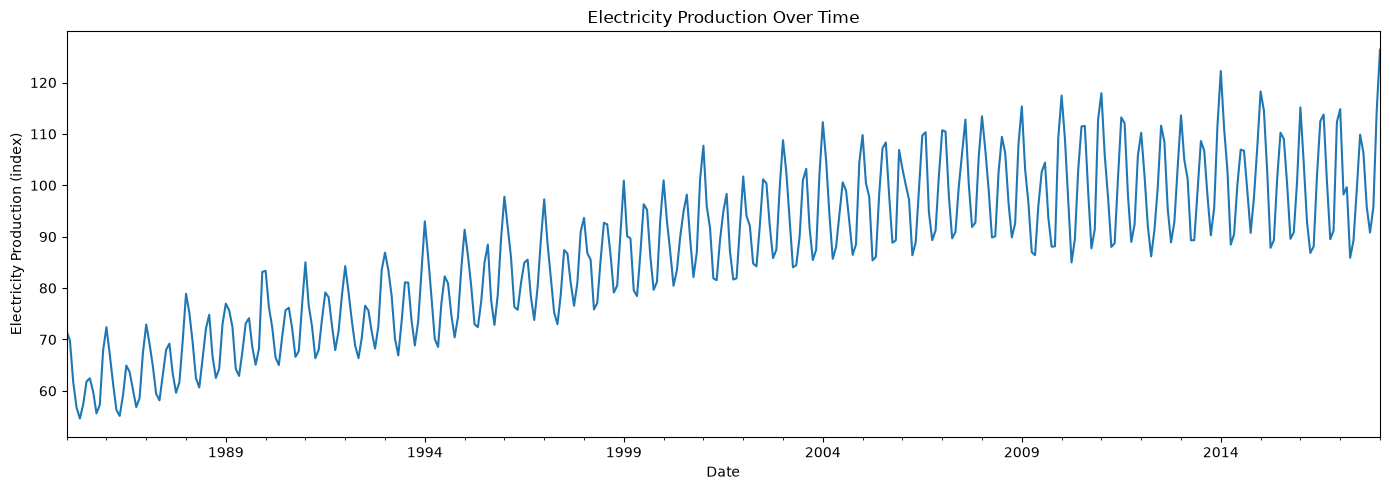

In [8]:
ax = series.plot(figsize=(14, 5))
ax.set_title("Electricity Production Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Electricity Production (index)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_series.png", dpi=150)
plt.show()

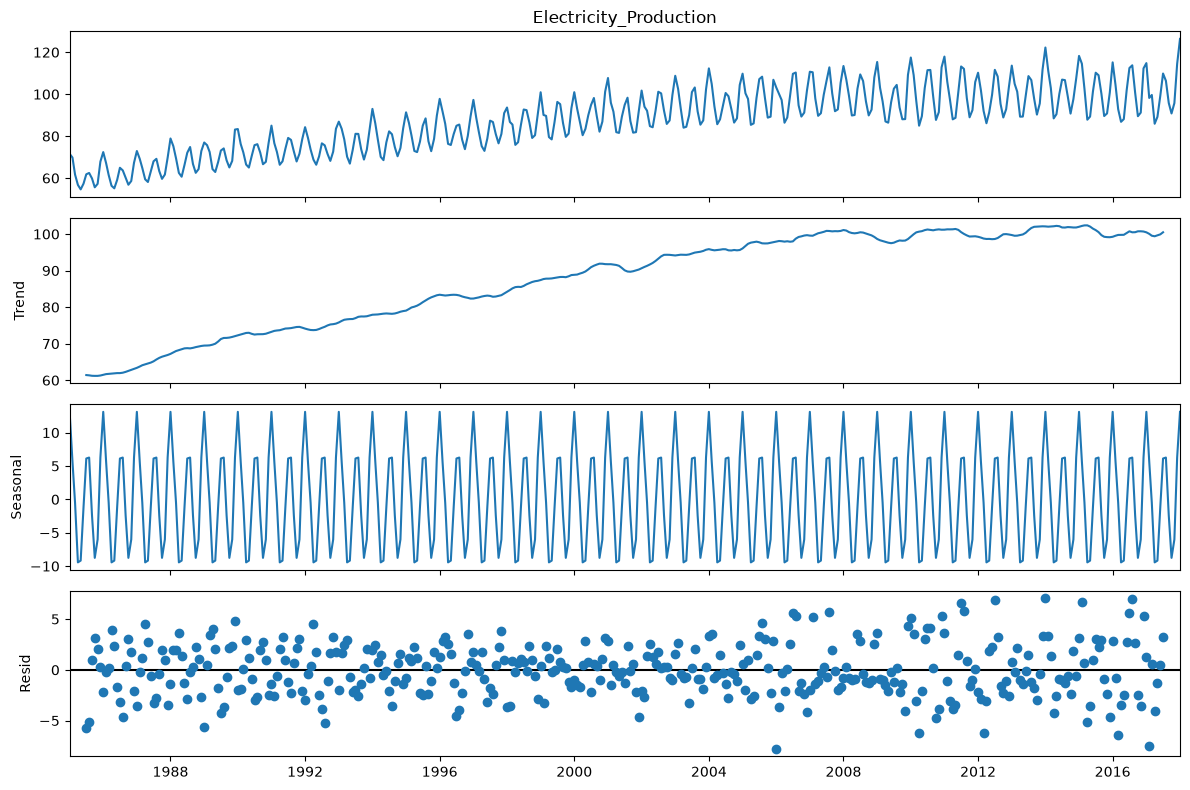

In [9]:
decomposition = seasonal_decompose(series, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_decomposition.png", dpi=150)
plt.show()

Strong upward trend up to the late 2000s, then a plateau, with a clear double seasonal peak each year (winter heating and summer cooling).

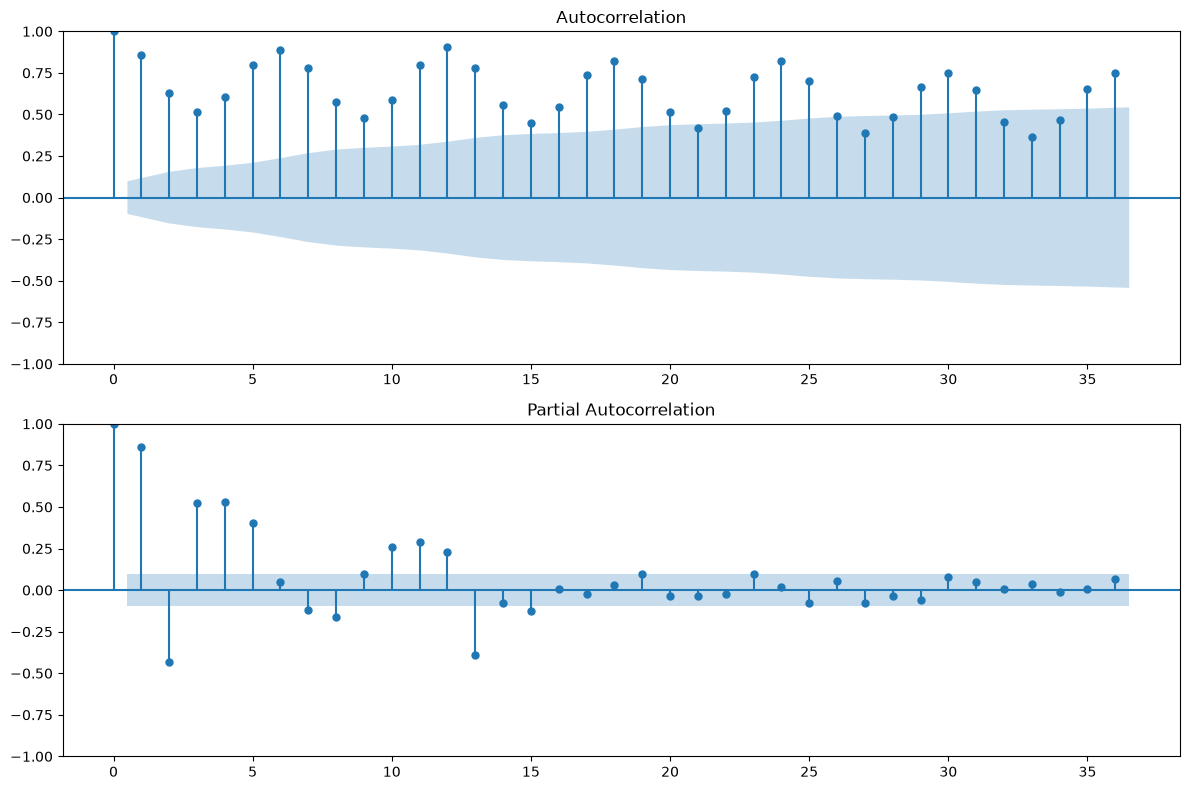

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(series, lags=36, ax=axes[0])
plot_pacf(series, lags=36, ax=axes[1])
plt.tight_layout()
plt.savefig(FIG_DIR / "03_acf_pacf.png", dpi=150)
plt.show()

## 4. Metrics

In [11]:
def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100,
    }

## 5. Single 12-month hold-out

The last 12 months are hidden from every model.

In [12]:
train = series.iloc[:-HORIZON]
test = series.iloc[-HORIZON:]

print("Training:", len(train))
print("Test:", len(test))
test

Training: 385
Test: 12


DATE
2017-02-01     98.2095
2017-03-01     99.6334
2017-04-01     85.9073
2017-05-01     89.2038
2017-06-01     99.1943
2017-07-01    109.8524
2017-08-01    106.3908
2017-09-01     95.8099
2017-10-01     90.8122
2017-11-01     95.7451
2017-12-01    114.4277
2018-01-01    126.3765
Name: Electricity_Production, dtype: float64

In [13]:
# 1. Seasonal naive
naive_forecast = train.iloc[-12:].values

# 2. SARIMA
sarima_fit = SARIMAX(
    train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)
).fit(disp=False)
sarima_forecast = sarima_fit.forecast(steps=HORIZON).values

# 3. Timestral (zero-shot: only sees the raw history)
holdout_forecast = forecaster.forecast(train.values, prediction_length=HORIZON)
timestral_forecast = holdout_forecast.median.detach().cpu().numpy().squeeze()

/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/timestral/forecaster.py:234: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  x = torch.as_tensor(context, dtype=torch.float32, device=self.device)


In [14]:
holdout_results = pd.DataFrame({
    "Seasonal Naive": metrics(test.values, naive_forecast),
    "SARIMA": metrics(test.values, sarima_forecast),
    "Timestral-28M": metrics(test.values, timestral_forecast),
}).T.round(3)

holdout_results.to_csv(RESULTS_DIR / "holdout_metrics.csv")
holdout_results

,MAE,RMSE,MAPE
Seasonal Naive,4.342,5.320,4.145
SARIMA,3.589,4.657,3.408
Timestral-28M,3.662,4.623,3.489


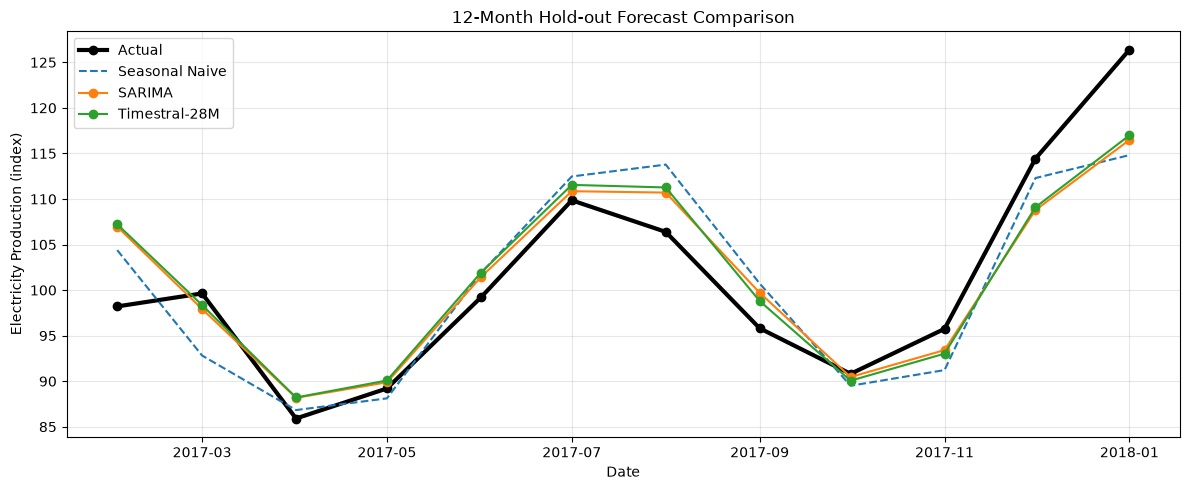

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, label="Actual", color="black", marker="o", linewidth=3)
plt.plot(test.index, naive_forecast, label="Seasonal Naive", linestyle="--")
plt.plot(test.index, sarima_forecast, label="SARIMA", marker="o")
plt.plot(test.index, timestral_forecast, label="Timestral-28M", marker="o")
plt.title("12-Month Hold-out Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Electricity Production (index)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_holdout_comparison.png", dpi=150)
plt.show()

## 6. Rolling-origin backtest

One hold-out year can flatter or punish any model by chance. Here every model is re-evaluated on each of the last 5 years, with an expanding training window. SARIMA is refitted per fold; Timestral just receives a longer context.

In [16]:
def rolling_backtest(series, forecaster, horizon=12, step=12, n_folds=5):
    results, predictions = [], []

    # Work backwards from the end so the last n_folds years are each a test window
    first_test_start = len(series) - (horizon + (n_folds - 1) * step)

    for fold in range(n_folds):
        test_start = first_test_start + fold * step
        train_fold = series.iloc[:test_start]
        test_fold = series.iloc[test_start:test_start + horizon]
        actual = test_fold.values

        print(f"Fold {fold + 1}: {test_fold.index[0].date()} to "
              f"{test_fold.index[-1].date()} | train size {len(train_fold)}")

        naive_pred = train_fold.iloc[-12:].values

        sarima_pred = (
            SARIMAX(train_fold, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
            .fit(disp=False)
            .forecast(steps=horizon)
            .values
        )

        fc = forecaster.forecast(train_fold.values, prediction_length=horizon)
        timestral_pred = fc.median.detach().cpu().numpy().squeeze()

        for name, pred in [
            ("Seasonal Naive", naive_pred),
            ("SARIMA", sarima_pred),
            ("Timestral-28M", timestral_pred),
        ]:
            results.append({
                "Fold": fold + 1,
                "Test_Start": test_fold.index[0],
                "Test_End": test_fold.index[-1],
                "Train_Size": len(train_fold),
                "Model": name,
                **metrics(actual, pred),
            })

        for i, date in enumerate(test_fold.index):
            predictions.append({
                "Fold": fold + 1,
                "Date": date,
                "Actual": actual[i],
                "Seasonal_Naive": naive_pred[i],
                "SARIMA": sarima_pred[i],
                "Timestral": timestral_pred[i],
            })

    return pd.DataFrame(results), pd.DataFrame(predictions)

In [17]:
results_df, predictions_df = rolling_backtest(
    series=series, forecaster=forecaster, horizon=HORIZON, step=12, n_folds=5
)
results_df.to_csv(RESULTS_DIR / "backtest_by_fold.csv", index=False)
results_df

/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Fold 1: 2013-02-01 to 2014-01-01 | train size 337


Fold 2: 2014-02-01 to 2015-01-01 | train size 349


/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Fold 3: 2015-02-01 to 2016-01-01 | train size 361


...

Fold 4: 2016-02-01 to 2017-01-01 | train size 373


/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Fold 5: 2017-02-01 to 2018-01-01 | train size 385


/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/jassingh/Documents/vs_projects/agentic_ai_basics/experiments/timestral-electricity-forecasting/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,Fold,Test_Start,Test_End,Train_Size,Model,MAE,RMSE,MAPE
0,1,2013-02-01,2014-01-01,337,Seasonal Naive,3.832808,4.798909,3.659531
1,1,2013-02-01,2014-01-01,337,SARIMA,2.573715,3.414671,2.424207
2,1,2013-02-01,2014-01-01,337,Timestral-28M,2.465288,3.392292,2.326795
3,2,2014-02-01,2015-01-01,349,Seasonal Naive,2.030708,2.678145,1.918889
4,2,2014-02-01,2015-01-01,349,SARIMA,1.863909,2.284547,1.847335
5,2,2014-02-01,2015-01-01,349,Timestral-28M,2.278417,2.771318,2.235677
6,3,2015-02-01,2016-01-01,361,Seasonal Naive,2.626642,3.358107,2.595480
7,3,2015-02-01,2016-01-01,361,SARIMA,2.659347,3.653321,2.655816
8,3,2015-02-01,2016-01-01,361,Timestral-28M,2.898783,3.867592,2.869341
9,4,2016-02-01,2017-01-01,373,Seasonal Naive,3.536458,5.479370,3.415304


In [18]:
summary = (
    results_df
    .groupby("Model")[["MAE", "RMSE", "MAPE"]]
    .agg(["mean", "std"])
    .round(3)
    .sort_values(("MAPE", "mean"))
)
summary.to_csv(RESULTS_DIR / "backtest_summary.csv")
summary

MAE          RMSE          MAPE       
                 mean    std   mean    std   mean    std
Model                                                   
SARIMA          2.749  0.637  3.536  0.847  2.671  0.592
Timestral-28M   2.794  0.537  3.551  0.722  2.708  0.503
Seasonal Naive  3.274  0.934  4.327  1.244  3.147  0.886

In [19]:
# Markdown version of the summary, ready to paste into the README
flat = summary.copy()
flat.columns = [f"{m} ({s})" for m, s in flat.columns]
print(flat.to_markdown())

| Model          |   MAE (mean) |   MAE (std) |   RMSE (mean) |   RMSE (std) |   MAPE (mean) |   MAPE (std) |
|:---------------|-------------:|------------:|--------------:|-------------:|--------------:|-------------:|
| SARIMA         |        2.749 |       0.637 |         3.536 |        0.847 |         2.671 |        0.592 |
| Timestral-28M  |        2.794 |       0.537 |         3.551 |        0.722 |         2.708 |        0.503 |
| Seasonal Naive |        3.274 |       0.934 |         4.327 |        1.244 |         3.147 |        0.886 |


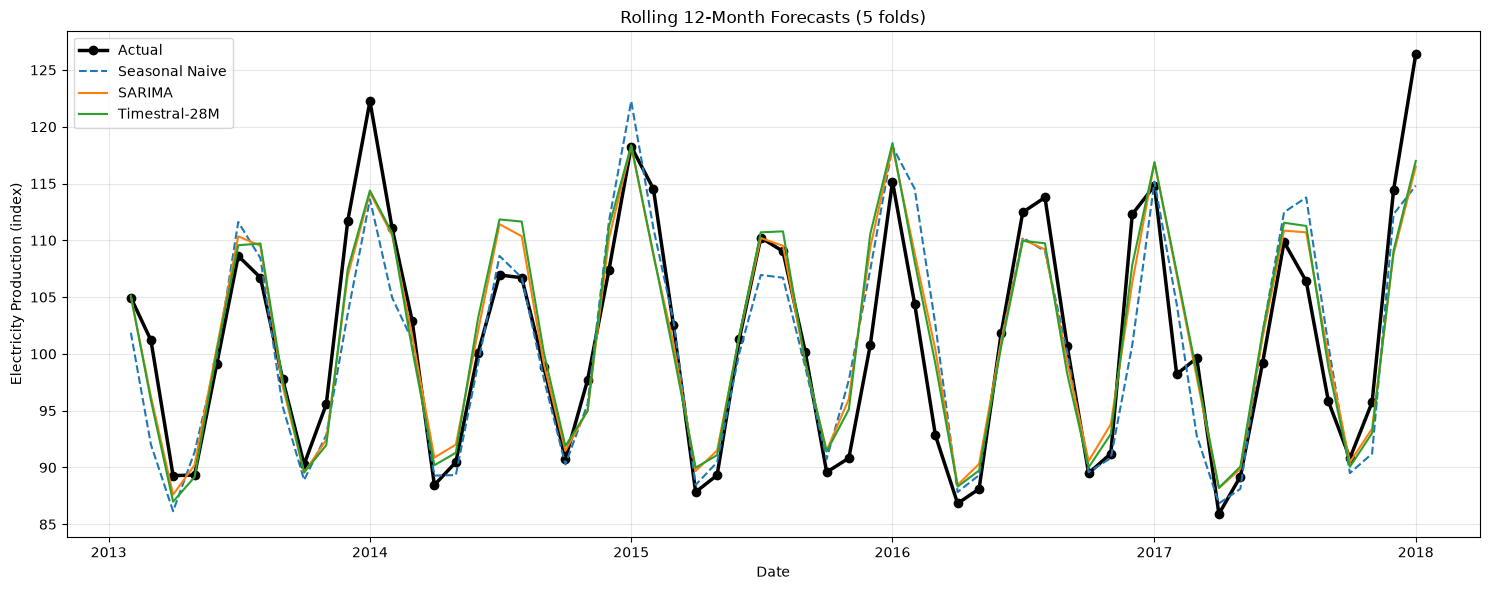

In [20]:
plt.figure(figsize=(15, 6))
plt.plot(predictions_df["Date"], predictions_df["Actual"],
         label="Actual", color="black", linewidth=2.5, marker="o")
plt.plot(predictions_df["Date"], predictions_df["Seasonal_Naive"],
         label="Seasonal Naive", linestyle="--")
plt.plot(predictions_df["Date"], predictions_df["SARIMA"], label="SARIMA")
plt.plot(predictions_df["Date"], predictions_df["Timestral"], label="Timestral-28M")
plt.title("Rolling 12-Month Forecasts (5 folds)")
plt.xlabel("Date")
plt.ylabel("Electricity Production (index)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_rolling_backtest.png", dpi=150)
plt.show()

## 7. Probabilistic forecast

Timestral returns 21 quantiles, not just a point forecast, so we get prediction intervals for free.

In [21]:
print(holdout_forecast.quantile_levels)
print("Quantiles shape:", holdout_forecast.quantiles.shape)

q = {
    level: holdout_forecast.quantile(level).detach().cpu().numpy().squeeze()
    for level in [0.05, 0.10, 0.50, 0.90, 0.95]
}

# Empirical coverage on the hold-out year
for lo, hi in [(0.05, 0.95), (0.10, 0.90)]:
    inside = ((test.values >= q[lo]) & (test.values <= q[hi])).mean()
    print(f"{int((hi - lo) * 100)}% interval covered {inside:.0%} of actuals")

(0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99)
Quantiles shape: torch.Size([1, 1, 12, 21])
89% interval covered 83% of actuals
80% interval covered 83% of actuals


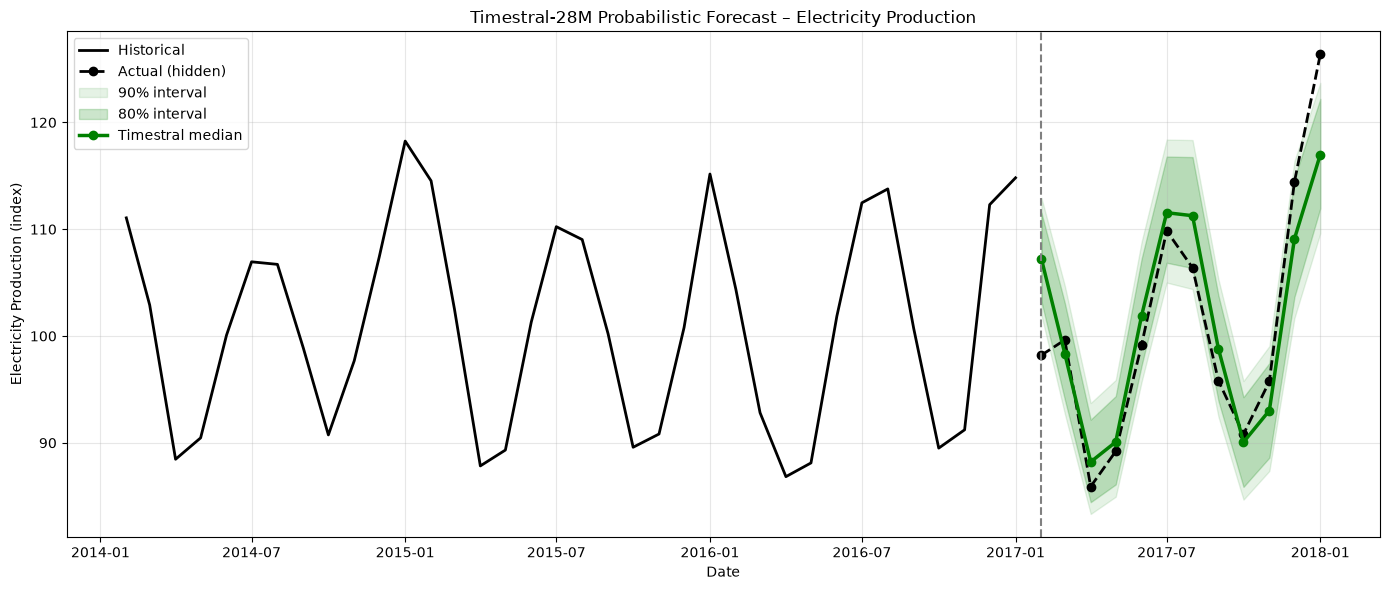

In [22]:
history = train.iloc[-36:]

plt.figure(figsize=(14, 6))
plt.plot(history.index, history.values, color="black", linewidth=2, label="Historical")
plt.plot(test.index, test.values, color="black", marker="o", linestyle="--",
         linewidth=2, label="Actual (hidden)")
plt.fill_between(test.index, q[0.05], q[0.95], color="green", alpha=0.10, label="90% interval")
plt.fill_between(test.index, q[0.10], q[0.90], color="green", alpha=0.20, label="80% interval")
plt.plot(test.index, q[0.50], color="green", marker="o", linewidth=2.5, label="Timestral median")
plt.axvline(test.index[0], color="grey", linestyle="--")
plt.title("Timestral-28M Probabilistic Forecast – Electricity Production")
plt.xlabel("Date")
plt.ylabel("Electricity Production (index)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_probabilistic_forecast.png", dpi=150)
plt.show()

## 8. Takeaways

_Fill in once the notebook has run, e.g.:_
- How Timestral-28M ranked against SARIMA and seasonal naive on mean MAPE across folds
- How stable each model was (std across folds)
- Whether the 80% / 90% intervals covered the actuals as expected
- Caveat: one series, one horizon. Foundation models shine most when you have many series and no time to tune each one.